# Notebook 01 — Phân tích khám phá dữ liệu (EDA)
**Đề tài R:** Xây dựng công cụ định giá token dựa trên dữ liệu thị trường
**Phụ trách:** Khanh (nhánh `feature/preprocess`) · phục vụ Mục 3.4–3.5 và minh họa Mục 2.3

**Phạm vi:** BTC, ETH, SOL, dữ liệu ngày trong 365 ngày gần nhất (CoinGecko: giá, volume, vốn hóa; DefiLlama: TVL, phí).

**Nội dung**
1. Nạp dữ liệu và kiểm tra chất lượng
2. Thống kê mô tả
3. Giá và khối lượng giao dịch theo thời gian
4. Lợi suất và độ biến động
5. Ma trận tương quan
6. Các chỉ số định giá: vận tốc V, NVT, MC/TVL
7. Thử nghiệm mô hình MV = PQ (walk-forward)
8. Kết luận

> Hình được lưu vào `reports/figures/`, bảng vào `reports/tables/` để chèn vào báo cáo.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

from src.preprocessing.clean import DataCleaner
from src.preprocessing.features import FeatureEngineer
from src.models.mv_pq import MVPQValuationModel
from src.evaluation.metrics import ValuationMetrics

FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR = ROOT / "reports" / "tables";  TAB_DIR.mkdir(parents=True, exist_ok=True)

# Màu cố định theo token (không đổi giữa các hình)
COLORS = {"BTC": "#257de0", "ETH": "#f47230", "SOL": "#00b894"}
INK, INK2, GRID = "#191919", "#666666", "#e6e6e6"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#257de0", "#ededed", "#ec4647"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.6,
    "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    print("Đã lưu", FIG_DIR.relative_to(ROOT) / f"{name}.png")

## 1. Nạp dữ liệu và kiểm tra chất lượng
Dữ liệu thô do `python -m src.preprocessing.build_dataset` tạo ra (có cache). Nếu chưa có file, notebook tự gọi API.

In [2]:
raw_path = ROOT / "data" / "processed" / "market_dataset_raw.csv"
if not raw_path.exists():
    from src.preprocessing.build_dataset import build_dataset
    build_dataset(["BTC", "ETH", "SOL"], days=365).to_csv(raw_path, index=False)

df_raw = pd.read_csv(raw_path, parse_dates=["date"])
df = DataCleaner.clean_token_dataset(df_raw)
df = FeatureEngineer.generate_features(df)
TOKENS = [t for t in COLORS if t in df["token"].unique()]

print(f"{len(df_raw)} dòng thô -> {len(df)} dòng sau làm sạch | {df['date'].min().date()} → {df['date'].max().date()}")
DataCleaner.quality_report(df)

1095 dòng thô -> 1095 dòng sau làm sạch | 2025-11-29 → 2026-11-28


,token,so_ngay,tu_ngay,den_ngay,ngay_noi_suy,ngay_bat_thuong,thieu_price_usd,thieu_volume_24h,thieu_market_cap,thieu_circulating_supply,thieu_tvl
0,BTC,365,2025-11-29,2026-11-28,0,0,0,0,0,0,0
1,ETH,365,2025-11-29,2026-11-28,0,0,0,0,0,0,0
2,SOL,365,2025-11-29,2026-11-28,0,0,0,0,0,0,0


In [3]:
# Những ô bị làm mịn ngoại lai (so sánh thô với sạch)
merged = df_raw.merge(df[["date", "token", "volume_24h", "tvl"]], on=["date", "token"], suffixes=("_raw", "_clean"))
changes = merged[(merged.volume_24h_raw.round(2) != merged.volume_24h_clean.round(2)) | (merged.tvl_raw.round(2) != merged.tvl_clean.round(2))]
changes[["date", "token", "volume_24h_raw", "volume_24h_clean", "tvl_raw", "tvl_clean"]]

,date,token,volume_24h_raw,volume_24h_clean,tvl_raw,tvl_clean
50,2026-01-18,BTC,3.391e+08,8.472e+09,7059367313,7.059e+09
103,2026-03-12,BTC,3.845e+08,8.399e+09,2644837149,2.645e+09
178,2026-05-26,BTC,2.223e+08,6.243e+09,4827274596,4.827e+09
364,2026-11-28,BTC,2.934e+10,2.934e+10,2039328088,2.117e+09
997,2026-08-23,SOL,7.502e+09,6.794e+09,5525320614,5.525e+09
1002,2026-08-28,SOL,7.039e+09,6.83e+09,5979216641,5.979e+09


## 2. Thống kê mô tả

In [4]:
desc_cols = ["price_usd", "volume_24h", "market_cap", "tvl", "fees_usd", "returns", "velocity"]
desc = df.groupby("token")[desc_cols].agg(["mean", "median", "std", "min", "max"]).T
desc.to_csv(TAB_DIR / "eda_thong_ke_mo_ta.csv")
desc

token                    BTC       ETH        SOL
price_usd  mean    7.498e+04     2,283      95.01
           median  7.572e+04     2,236      86.94
           std         9,750       450      20.95
           min     5.857e+04     1,566      62.18
           max      9.69e+04     3,352      146.5
volume_24h mean    3.502e+10 1.612e+10  3.227e+09
           median  3.252e+10 1.434e+10  3.014e+09
           std      1.59e+10 8.536e+09  1.502e+09
           min     6.243e+09  2.84e+09  6.469e+08
           max     1.291e+11 6.269e+10  1.102e+10
market_cap mean    1.502e+12 2.779e+11  5.476e+10
           median  1.517e+12 2.732e+11  4.983e+10
           std      1.94e+11 5.444e+10  1.162e+10
           min     1.174e+12 1.908e+11  3.598e+10
           max     1.936e+12 4.069e+11  8.281e+10
tvl        mean    4.511e+09 4.843e+10  6.114e+09
           median  4.174e+09 4.632e+10  5.755e+09
           std     1.115e+09 1.036e+10    1.3e+09
           min     2.117e+09 3.389e+10  4.381e+09
           max     7.161e+09 7.241e+10  9.214e+09
fees_usd   mean    2.112e+05 4.651e+05   6.24e+05
           median  2.021e+05 3.356e+05   5.78e+05
           std     5.182e+04 5.144e+05  2.168e+05
           min     1.088e+05 1.326e+05  2.691e+05
           max     5.821e+05 6.579e+06    1.4e+06
returns    mean    -0.001147 -0.001652  -0.001791
           median -0.0006593 4.871e-05 -0.0008026
           std       0.02316   0.03167    0.03248
           min       -0.1517   -0.1614    -0.1605
           max        0.1128    0.1613     0.1068
velocity   mean        8.563     21.32      21.62
           median      8.166     19.77      20.21
           std         3.899     11.17      9.546
           min         1.476     4.519      5.383
           max         37.57     92.01      81.61

## 3. Giá và khối lượng giao dịch theo thời gian
Giá và volume dùng hai hàng biểu đồ riêng (không dùng trục kép). Hình dưới chuẩn hóa giá về 100 tại ngày đầu để so sánh hiệu suất giữa các token.

Đã lưu reports\figures\eda_gia_volume.png


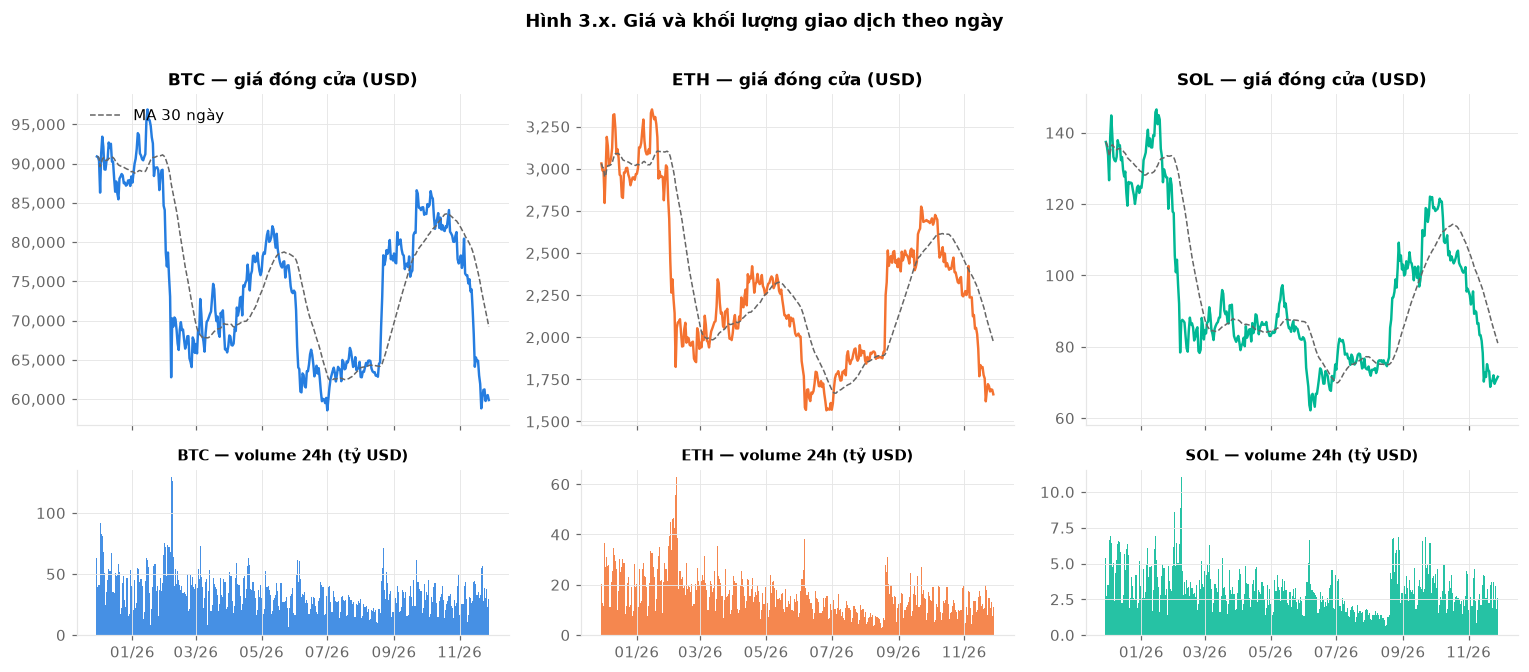

In [5]:
fig, axes = plt.subplots(2, len(TOKENS), figsize=(14, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for i, t in enumerate(TOKENS):
    g = df[df.token == t]
    ax = axes[0, i]
    ax.plot(g.date, g.price_usd, color=COLORS[t])
    ax.plot(g.date, g.ma_30, color=INK2, lw=1, ls="--", label="MA 30 ngày")
    ax.set_title(f"{t} — giá đóng cửa (USD)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    if i == 0: ax.legend(loc="upper left")
    ax = axes[1, i]
    ax.bar(g.date, g.volume_24h / 1e9, width=1.0, color=COLORS[t], alpha=0.85)
    ax.set_title(f"{t} — volume 24h (tỷ USD)", fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
fig.suptitle("Hình 3.x. Giá và khối lượng giao dịch theo ngày", fontweight="bold", y=1.01)
fig.tight_layout(); save(fig, "eda_gia_volume"); plt.show()

Đã lưu reports\figures\eda_gia_chuan_hoa.png


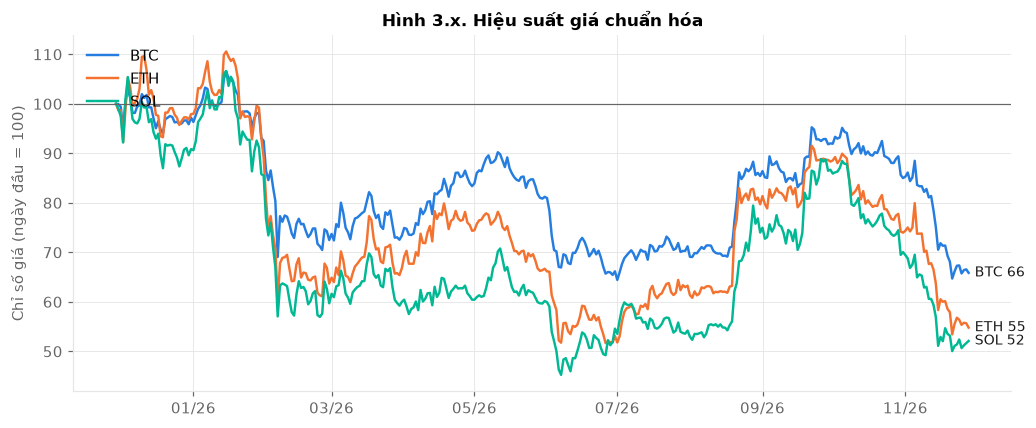

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for t in TOKENS:
    g = df[df.token == t]
    idx = g.price_usd / g.price_usd.iloc[0] * 100
    ax.plot(g.date, idx, color=COLORS[t], label=t)
    ax.annotate(f"{t} {idx.iloc[-1]:.0f}", (g.date.iloc[-1], idx.iloc[-1]), xytext=(4, 0),
                textcoords="offset points", va="center", color=INK, fontsize=9)
ax.axhline(100, color=INK2, lw=0.8)
ax.set_ylabel("Chỉ số giá (ngày đầu = 100)")
ax.set_title("Hình 3.x. Hiệu suất giá chuẩn hóa")
ax.legend(loc="upper left"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
save(fig, "eda_gia_chuan_hoa"); plt.show()

## 4. Lợi suất và độ biến động

Đã lưu reports\figures\eda_loi_suat_bien_dong.png


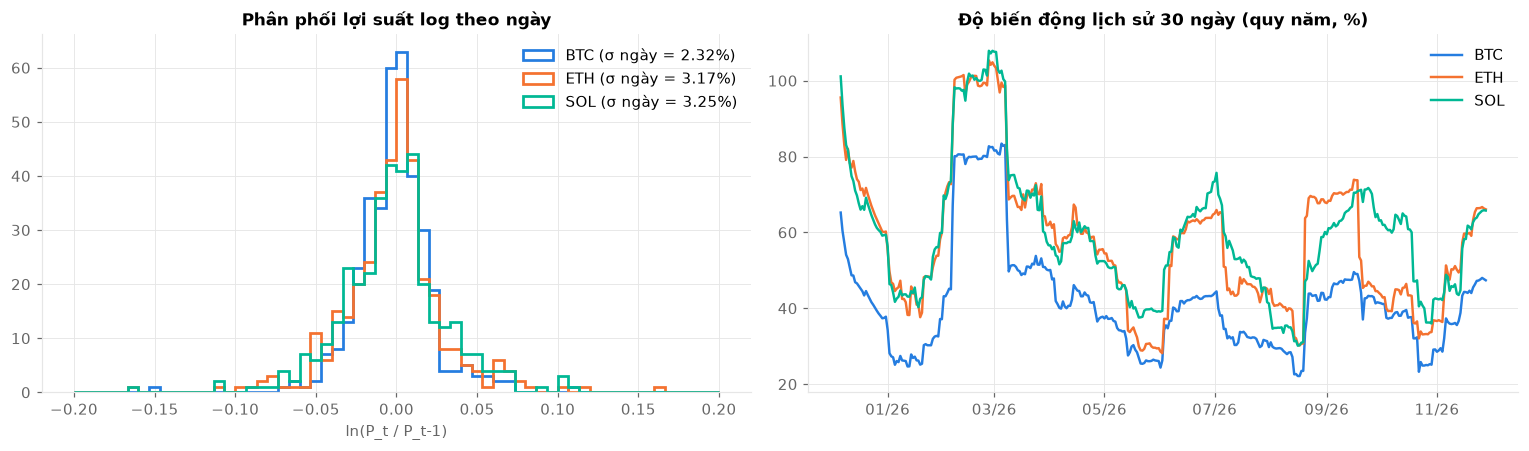

,trung_binh,do_lech_chuan,lech,nhon,nho_nhat,lon_nhat,bien_dong_quy_nam
token,,,,,,,
BTC,-0.001147,0.02316,-0.271,6.675,-0.1517,0.1128,0.4426
ETH,-0.001652,0.03167,0.1106,4.635,-0.1614,0.1613,0.605
SOL,-0.001791,0.03248,-0.1278,2.546,-0.1605,0.1068,0.6206


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
bins = np.linspace(-0.2, 0.2, 61)
for t in TOKENS:
    r = df.loc[df.token == t, "returns"].dropna()
    axes[0].hist(r, bins=bins, histtype="step", lw=1.8, color=COLORS[t], label=f"{t} (σ ngày = {r.std():.2%})")
axes[0].set_title("Phân phối lợi suất log theo ngày"); axes[0].set_xlabel("ln(P_t / P_t-1)"); axes[0].legend()
for t in TOKENS:
    g = df[df.token == t]
    axes[1].plot(g.date, g.volatility_30d * 100, color=COLORS[t], label=t)
axes[1].set_title("Độ biến động lịch sử 30 ngày (quy năm, %)"); axes[1].legend()
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
fig.tight_layout(); save(fig, "eda_loi_suat_bien_dong"); plt.show()

ret_stats = df.groupby("token")["returns"].agg(
    trung_binh="mean", do_lech_chuan="std", lech="skew", nhon=lambda s: s.kurt(), nho_nhat="min", lon_nhat="max")
ret_stats["bien_dong_quy_nam"] = ret_stats["do_lech_chuan"] * np.sqrt(365)
ret_stats.to_csv(TAB_DIR / "eda_loi_suat.csv"); ret_stats

## 5. Ma trận tương quan
Tương quan được tính **riêng từng token** và trên **thay đổi log theo ngày** chứ không trên mức giá trị:
hai chuỗi cùng có xu hướng sẽ cho tương quan mức rất cao dù không liên quan (tương quan giả).
Gộp nhiều token rồi tính tương quan mức cũng sai vì quy mô giá khác nhau hàng nghìn lần.

Đã lưu reports\figures\eda_tuong_quan.png


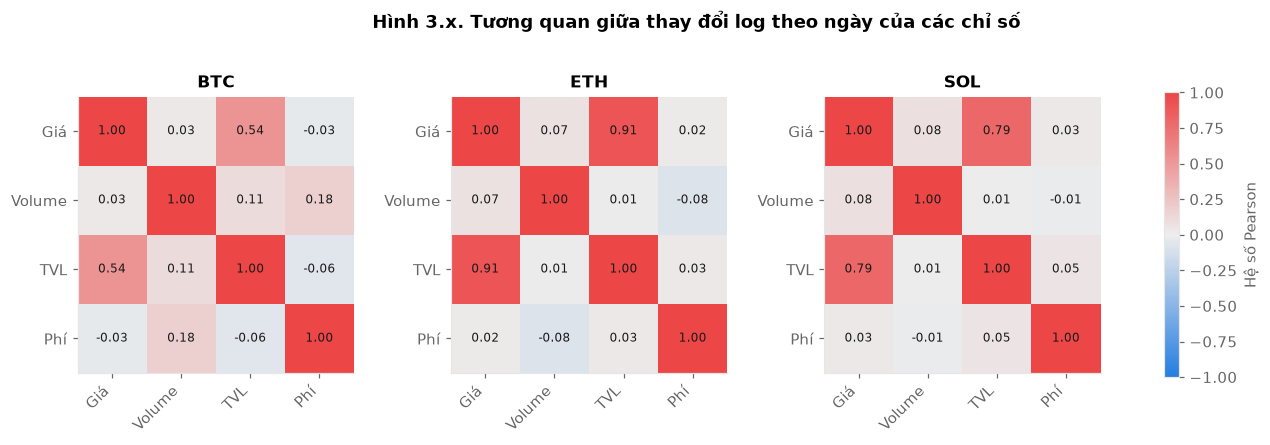

In [8]:
corr_vars = {"price_usd": "Giá", "volume_24h": "Volume", "tvl": "TVL", "fees_usd": "Phí"}  # bỏ Vốn hóa: = Giá × cung (gần như không đổi) nên tương quan ≈ 1
fig, axes = plt.subplots(1, len(TOKENS), figsize=(15, 4.2), gridspec_kw={"wspace": 0.35})
corr_tables = {}
for ax, t in zip(axes, TOKENS):
    g = df[df.token == t].set_index("date")[list(corr_vars)]
    chg = np.log(g.where(g > 0)).diff().rename(columns=corr_vars)
    c = chg.corr(); corr_tables[t] = c
    im = ax.imshow(c, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(c)), c.columns, rotation=45, ha="right"); ax.set_yticks(range(len(c)), c.index)
    ax.grid(False)
    for i in range(len(c)):
        for j in range(len(c)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color=INK)
    ax.set_title(t)
fig.colorbar(im, ax=axes, shrink=0.8, label="Hệ số Pearson")
fig.suptitle("Hình 3.x. Tương quan giữa thay đổi log theo ngày của các chỉ số", fontweight="bold")
save(fig, "eda_tuong_quan"); plt.show()
pd.concat(corr_tables).round(2).to_csv(TAB_DIR / "eda_tuong_quan.csv")

In [9]:
# |lợi suất| (độ lớn biến động) so với thay đổi volume: volume tăng khi giá biến động mạnh, bất kể hướng
abs_corr = {}
for t in TOKENS:
    g = df[df.token == t]
    abs_corr[t] = g["returns"].abs().corr(np.log(g["volume_24h"]).diff())
print("Tương quan |lợi suất| – Δlog(volume):", {k: round(v, 2) for k, v in abs_corr.items()})

Tương quan |lợi suất| – Δlog(volume): {'BTC': np.float64(0.31), 'ETH': np.float64(0.36), 'SOL': np.float64(0.37)}


In [10]:
# Tóm tắt các cặp tương quan quan trọng
pairs = [("Giá", "Volume"), ("Giá", "TVL"), ("Volume", "Phí")]
pd.DataFrame({t: {f"{a}–{b}": corr_tables[t].loc[a, b] for a, b in pairs} for t in TOKENS}).round(2)

,BTC,ETH,SOL
Giá–Volume,0.03,0.07,0.08
Giá–TVL,0.54,0.91,0.79
Volume–Phí,0.18,-0.08,-0.01


## 6. Các chỉ số định giá: vận tốc V, NVT, MC/TVL
NVT ở đây dùng volume sàn (`volume_24h`) do chưa có volume on-chain; MC/TVL của BTC rất lớn vì TVL trên Bitcoin nhỏ so với vốn hóa.

Đã lưu reports\figures\eda_chi_so_dinh_gia.png


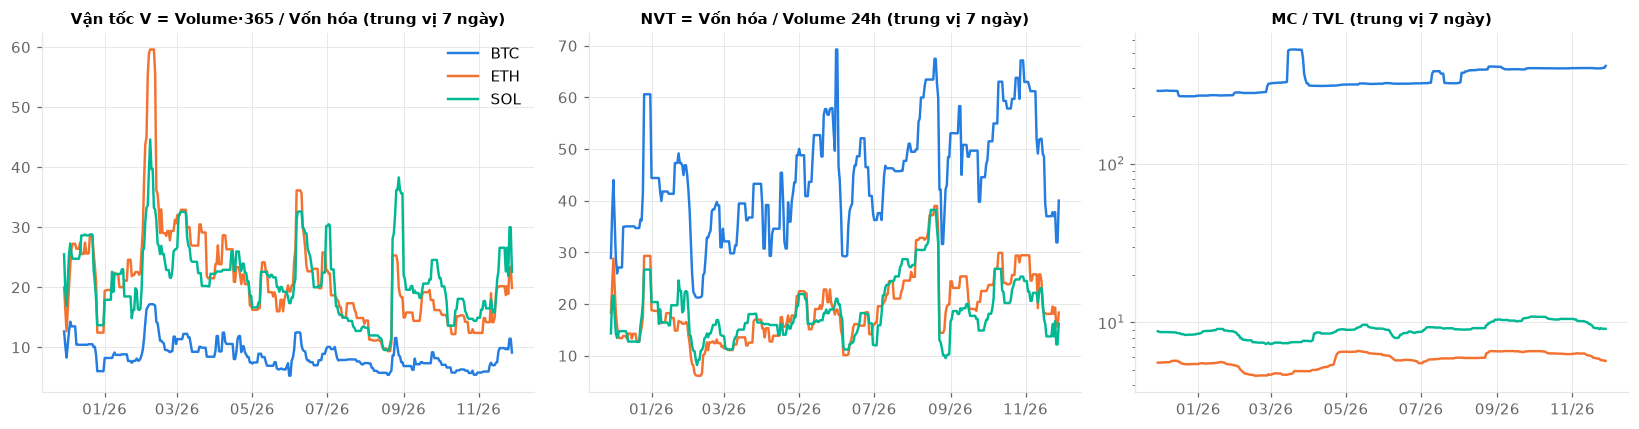

,velocity,nvt_ratio,mc_tvl_ratio,liquidity_score
token,,,,
BTC,8.166,44.7,321.8,1
ETH,19.77,18.46,5.855,1
SOL,20.21,18.06,8.986,1


In [11]:
metrics = [("velocity", "Vận tốc V = Volume·365 / Vốn hóa"), ("nvt_ratio", "NVT = Vốn hóa / Volume 24h"), ("mc_tvl_ratio", "MC / TVL")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, title) in zip(axes, metrics):
    for t in TOKENS:
        g = df[df.token == t]
        ax.plot(g.date, g[col].rolling(7, min_periods=1).median(), color=COLORS[t], label=t)
    ax.set_title(title + " (trung vị 7 ngày)", fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
    if col == "mc_tvl_ratio": ax.set_yscale("log")
axes[0].legend()
fig.tight_layout(); save(fig, "eda_chi_so_dinh_gia"); plt.show()

df.groupby("token")[["velocity", "nvt_ratio", "mc_tvl_ratio", "liquidity_score"]].median()

## 7. Thử nghiệm mô hình MV = PQ (walk-forward)
$P_{fair,t} = \dfrac{\overline{Volume}_{7d,t}\times 365}{\hat V_t \cdot S_t}$, với $\hat V_t$ là trung vị vận tốc của 90 ngày **trước** ngày t (không dùng dữ liệu tương lai).
14 ngày đầu chưa đủ lịch sử nên không có giá trị.

In [12]:
results, rows = {}, []
for t in TOKENS:
    model = MVPQValuationModel(velocity_window=90)
    res = model.analyze_valuation(df[df.token == t], walk_forward=True)
    results[t] = res
    ok = res.dropna(subset=["fair_price"])
    m = ValuationMetrics.evaluate_all(ok.price_usd, ok.fair_price)
    last = res.iloc[-1]
    rows.append({"token": t, "gia_thi_truong": last.price_usd, "gia_mvpq": last.fair_price,
                 "do_lech_pct": last.mispricing_pct, "tin_hieu": last.signal, **m,
                 "ty_le_ngay_fair_value_pct": (ok.signal == "Fair Value").mean() * 100})
mvpq_table = pd.DataFrame(rows).set_index("token")
mvpq_table.to_csv(TAB_DIR / "mvpq_ket_qua.csv"); mvpq_table

,gia_thi_truong,gia_mvpq,do_lech_pct,tin_hieu,MAE,RMSE,MAPE,ty_le_ngay_fair_value_pct
token,,,,,,,,
BTC,5.987e+04,9.434e+04,-36.53,Undervalued,1.451e+04,2.219e+04,20.11,42.45
ETH,"1,661","2,341",-29.03,Undervalued,510.9,800.3,24.19,32.19
SOL,71.59,89.12,-19.67,Undervalued,19.66,29.82,22.07,41.31


Đã lưu reports\figures\mvpq_so_sanh_gia.png


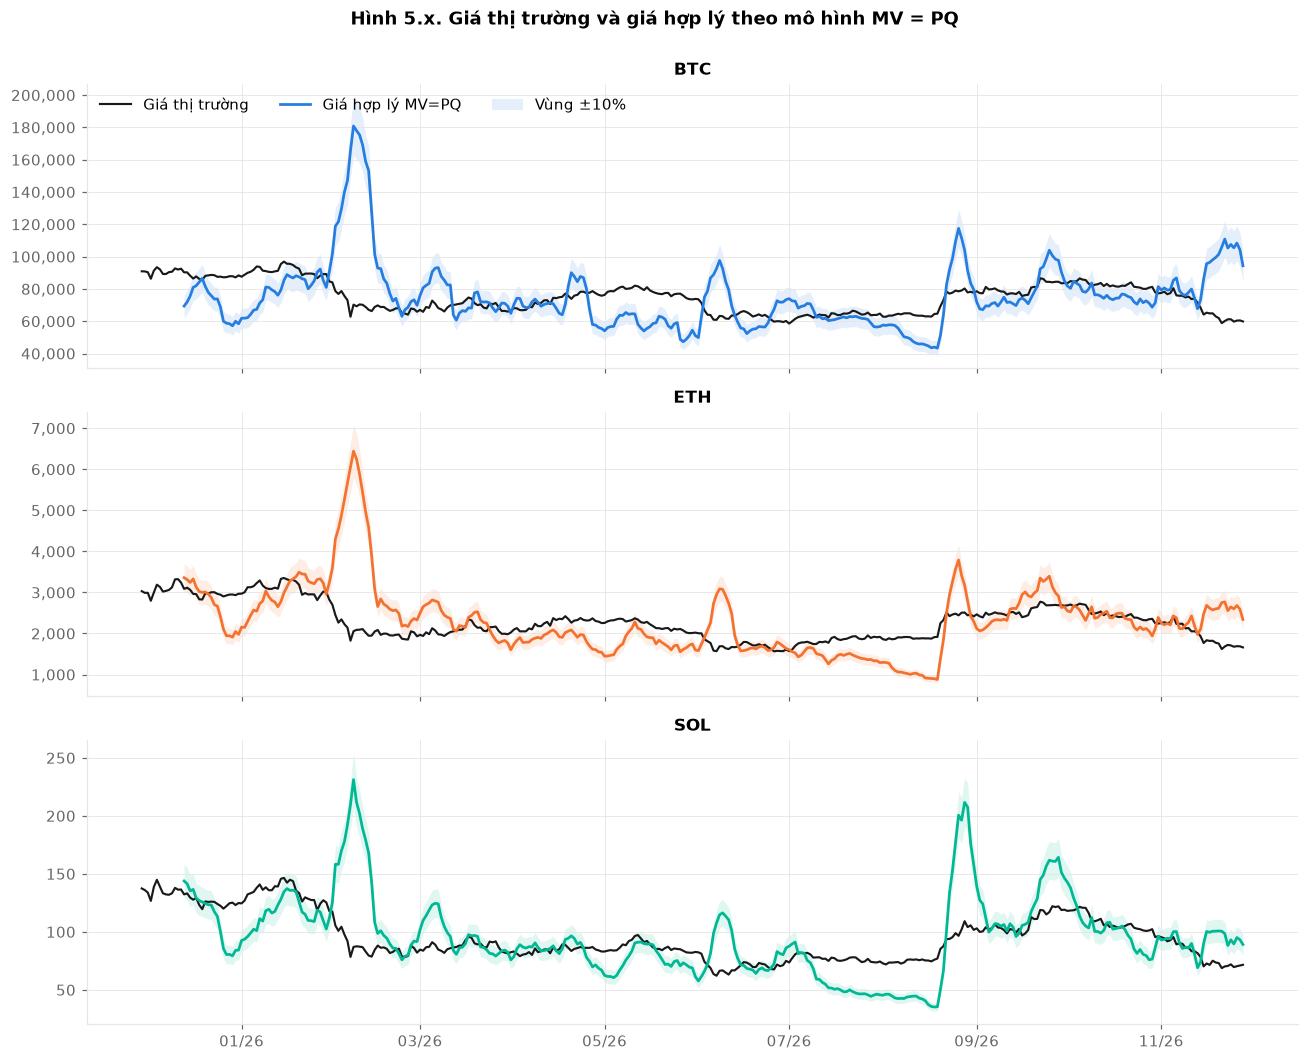

In [13]:
fig, axes = plt.subplots(len(TOKENS), 1, figsize=(12, 3.2 * len(TOKENS)), sharex=True)
for ax, t in zip(axes, TOKENS):
    r = results[t]
    ax.plot(r.date, r.price_usd, color=INK, lw=1.4, label="Giá thị trường")
    ax.plot(r.date, r.fair_price, color=COLORS[t], lw=1.8, label="Giá hợp lý MV=PQ")
    ax.fill_between(r.date, r.fair_price * 0.9, r.fair_price * 1.1, color=COLORS[t], alpha=0.12, lw=0, label="Vùng ±10%")
    ax.set_title(f"{t}"); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].legend(loc="upper left", ncol=3)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
fig.suptitle("Hình 5.x. Giá thị trường và giá hợp lý theo mô hình MV = PQ", fontweight="bold", y=1.0)
fig.tight_layout(); save(fig, "mvpq_so_sanh_gia"); plt.show()

## 8. Kết luận EDA (số liệu 29/11/2025 – 28/11/2026)

**Chất lượng dữ liệu.** Cả ba token đủ 365 ngày, không thiếu giá, volume, vốn hóa hay TVL. Bước làm sạch phát hiện 3 ngày CoinGecko trả volume BTC thấp bất thường (≈0,2–0,4 tỷ USD so với mức thường ≈30 tỷ) và đã kéo về mức hợp lý theo trung vị trượt. Ngoài ra có 2 ngày volume SOL tăng đột biến được làm mịn nhẹ. Đây là lý do bắt buộc phải tiền xử lý trước khi định giá.

**Xu hướng và biến động.** Đây là một năm giảm giá: BTC −34%, ETH −45%, SOL −48%, mức sụt giảm lớn nhất từ đỉnh lần lượt −40%, −53% và −58%. Độ biến động quy năm của BTC thấp nhất (≈44%), ETH và SOL cao hơn rõ rệt (≈60–62%). Phân phối lợi suất có đuôi dày (độ nhọn dư 2,5–6,7), nên dùng trung vị thay cho trung bình là hợp lý.

**Tương quan** (tính trên thay đổi log theo ngày, riêng từng token):
- Thay đổi giá gần như không tương quan với thay đổi volume (r ≈ 0,03–0,08). Tuy vậy, *độ lớn* biến động giá |lợi suất| lại tương quan dương với volume (r ≈ 0,31–0,37): volume tăng khi thị trường biến động mạnh, bất kể giá tăng hay giảm.
- TVL tương quan mạnh với giá (ETH 0,91; SOL 0,79; BTC 0,54), vì TVL được tính bằng USD nên tăng giảm theo giá tài sản bị khóa. Cần lưu ý điều này khi dùng MC/TVL cho mô hình so sánh.
- Phí giao dịch gần như không tương quan với volume giao dịch trên sàn trong ngắn hạn.

**Chỉ số định giá.** Vận tốc trung vị của BTC ≈ 8, thấp hơn hẳn ETH và SOL (≈ 20), phù hợp vai trò "lưu trữ giá trị" của BTC. NVT của BTC (≈ 45) cao hơn khoảng 2,5 lần ETH và SOL (≈ 18). MC/TVL của BTC rất lớn (≈ 320) vì DeFi trên Bitcoin nhỏ, nên MC/TVL không phù hợp để định giá BTC.

**Mô hình MV = PQ (walk-forward, V̂ = trung vị 90 ngày trước).** Trên 351 ngày đánh giá, MAPE lần lượt là BTC 20,1%, ETH 24,2%, SOL 22,1%; sai số tương đối trung vị 12–16%. Giá hợp lý tăng vọt (gấp 2,6–3,3 lần giá thị trường) đúng vào đợt bán tháo đầu tháng 2/2026. Nguyên nhân là volume hoảng loạn làm PQ tăng mạnh trong khi V̂ vẫn theo chuẩn cũ. Đây là hạn chế cốt lõi của MV = PQ: mô hình hiểu nhầm volume đầu cơ hay bán tháo là "nhu cầu sử dụng". Vì vậy MV = PQ chỉ nên là một thành phần trong ensemble, kèm cảnh báo khi `is_anomaly` hoặc khi volatility cao. Hạn chế này cần được nêu ở Mục 5.4.

> Ghi chú: dữ liệu on-chain (số địa chỉ hoạt động, volume on-chain) chưa có trong bộ dữ liệu này. Khi collectors on-chain hoàn tất, cần chạy lại notebook để bổ sung phân tích NVT on-chain và Metcalfe.
